# 01 · Data Preparation & Exploration (Member B)

This notebook walks through the data pipeline step by step and produces the statistics and figures for
**Report Section 3 (Dataset and Problem Formulation)**.

It does not replace the `.py` scripts: it **calls** them. `src/data_preprocessing.py` and `src/dataset.py` remain the
single source of truth that A and C import.

**Run locally:** open this notebook from the `HealthRank/` project folder (or `notebooks/`).
**Run on Colab (recommended, Jupyter + matplotlib preinstalled):** run the first cell and upload `HealthRank_full_latest.zip` when asked.
**Run locally:** `pip install -r requirements.txt` first (includes matplotlib and Jupyter).

In [1]:
import os, sys

# --- locate the project root (works locally and on Colab) ---
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
if not os.path.exists("src/dataset.py"):
    if "google.colab" in sys.modules:
        from google.colab import files
        import zipfile
        print("Upload HealthRank_full_latest.zip")
        up = files.upload()
        zipfile.ZipFile(next(iter(up))).extractall(".")
        os.chdir("HealthRank")
    else:
        raise FileNotFoundError("Open this notebook from the HealthRank project folder.")
sys.path.insert(0, os.getcwd())
print("Project root:", os.getcwd())

Upload HealthRank_full_latest.zip


Saving HealthRank_full_latest_3.zip to HealthRank_full_latest_3.zip
Project root: /content/HealthRank


## Step 1 · Look at the raw MealRec+ files

Source: Li et al., *MealRec+*, SIGIR '24 (github.com/WUT-IDEA/MealRecPlus). We use the denser version **MealRec+H**.
Every file is tab-separated indices, e.g. `user_meal_train.txt` = `[user index] [meal index]`.

In [2]:
import pandas as pd
RAW = "data/raw/MealRec+H"
for f in ["user_meal_train.txt", "meal_course.txt", "course_category.txt", "healthiness/meal_fsa.txt", "healthiness/meal_who.txt"]:
    df = pd.read_csv(f"{RAW}/{f}", sep="\t", header=None)
    print(f"{f:28s} rows={len(df):>6}   first row: {df.iloc[0].tolist()}")

user_meal_train.txt          rows= 37413   first row: [153, 43]
meal_course.txt              rows= 11451   first row: [674, 851]
course_category.txt          rows= 11451   first row: [851, 0]
healthiness/meal_fsa.txt     rows=  3817   first row: [10.333333333333334]
healthiness/meal_who.txt     rows=  3817   first row: [2.0]


## Step 2 · Run the preprocessing script

`src/data_preprocessing.py` validates everything **before** writing (split overlaps, ID ranges, category conflicts,
missing health values) and stops with an error if a critical check fails. It then writes the unified CSVs to
`data/processed/MealRec+H/`.

In [3]:
from src.data_preprocessing import main
main("MealRec+H")

NOTE: course.csv not found -> skipped course_info.csv (only needed for demo names/images).
{
  "dataset": "MealRec+H",
  "n_users": 1575,
  "n_meals": 3817,
  "n_courses": 7280,
  "n_courses_used_in_meals": 942,
  "n_interactions": 46767,
  "density_%": 0.778,
  "split_sizes": {
    "train": 37413,
    "val": 4677,
    "test": 4677
  },
  "split_ratio": {
    "train": 0.8,
    "val": 0.1,
    "test": 0.1
  },
  "avg_meals_per_user_train": 23.75,
  "courses_per_meal": {
    "3": 3817
  },
  "fsa_range": [
    5.0,
    11.666666666666666
  ],
  "who_range": [
    0.3333333333333333,
    5.333333333333333
  ],
  "health_score_formula": "0.5*(1-minmax(FSA)) + 0.5*minmax(WHO)",
  "users_in_test": 1114,
  "cold_start_test_users": 0,
  "warnings": []
}

All critical checks passed. No warnings.
Outputs written to /content/HealthRank/data/processed/MealRec+H


## Step 3 · Load with the shared loader (what A and C use)

In [4]:
from src.dataset import load_data
data = load_data("MealRec+H")
print(f"users={data.n_users}  meals={data.n_meals}")
print(f"train={len(data.train)}  val={len(data.val)}  test={len(data.test)}  test users={len(data.test_items)}")
data.meal_health.head()

users=1575  meals=3817
train=37413  val=4677  test=4677  test users=1114


,meal_id,fsa,who,fsa_norm,who_norm,health_score
0,0,10.333333,2.000000,0.20,0.333333,0.266667
1,1,10.333333,1.666667,0.20,0.266667,0.233333
2,2,10.333333,2.333333,0.20,0.400000,0.300000
3,3,9.666667,1.666667,0.30,0.266667,0.283333
4,4,9.333333,1.333333,0.35,0.200000,0.275000


## Step 4 · Dataset statistics (Table for Section 3)

In [5]:
import json, numpy as np
s = json.load(open("data/processed/MealRec+H/stats.json"))
per_user = data.train.groupby("user_id").size()
per_meal = data.train.groupby("meal_id").size()
table = pd.DataFrame([
    ("Users", f"{s['n_users']:,}"),
    ("Meals (3 courses each)", f"{s['n_meals']:,}"),
    ("Courses (total / used in meals)", f"{s['n_courses']:,} / {s['n_courses_used_in_meals']:,}"),
    ("User–meal interactions", f"{s['n_interactions']:,}"),
    ("Density", f"{s['density_%']}%"),
    ("Train / Val / Test", " / ".join(f"{v:,}" for v in s['split_sizes'].values())),
    ("Meals per user (train): mean / median", f"{per_user.mean():.1f} / {per_user.median():.0f}"),
    ("Interactions per observed meal (train): mean / max", f"{per_meal.mean():.1f} / {per_meal.max()}"),
    ("Meals with no train interactions", f"{data.n_meals - len(per_meal):,}"),
    ("Users with test interactions", f"{s['users_in_test']:,}"),
    ("FSA range (lower = healthier)", f"{s['fsa_range'][0]:.2f} – {s['fsa_range'][1]:.2f}"),
    ("WHO range (higher = healthier)", f"{s['who_range'][0]:.2f} – {s['who_range'][1]:.2f}"),
], columns=["Statistic", "MealRec+H"])
os.makedirs("results", exist_ok=True)
table.to_csv("results/dataset_stats_table.csv", index=False)
table

,Statistic,MealRec+H
0,Users,"1,575"
1,Meals (3 courses each),"3,817"
2,Courses (total / used in meals),"7,280 / 942"
3,User–meal interactions,"46,767"
4,Density,0.778%
5,Train / Val / Test,"37,413 / 4,677 / 4,677"
6,Meals per user (train): mean / median,23.8 / 9
7,Interactions per observed meal (train): mean /...,9.8 / 86
8,Meals with no train interactions,7
9,Users with test interactions,"1,114"


## Step 5 · Figures for the report

Saved to `figures/` as PNG (300 dpi).

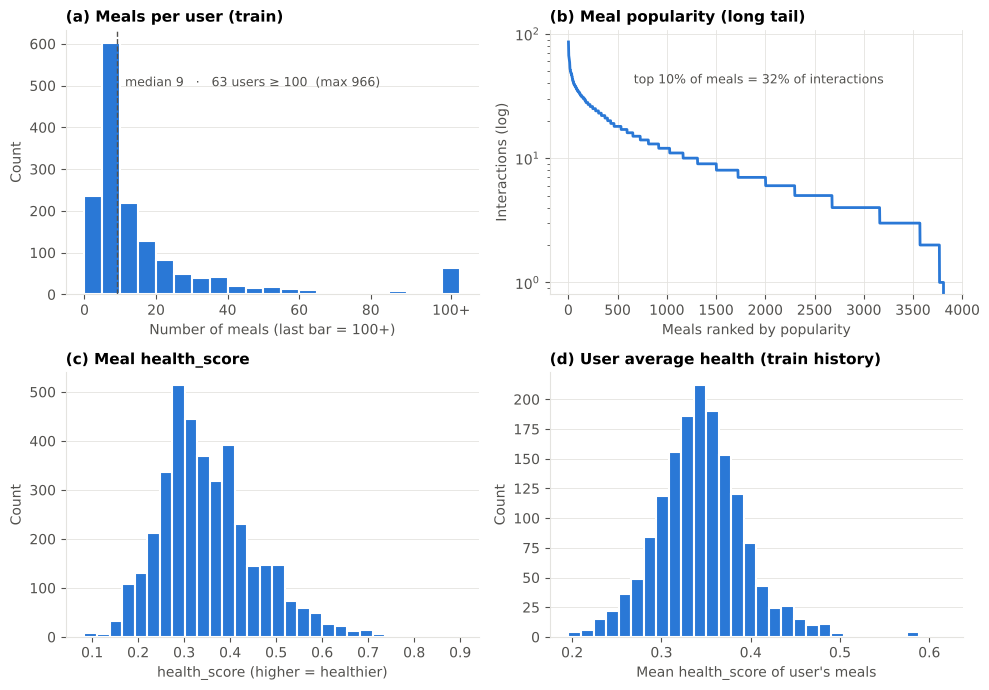

In [6]:
import matplotlib.pyplot as plt
os.makedirs("figures", exist_ok=True)
BLUE, TEXT2, GRID = "#2a78d6", "#52514e", "#e4e3df"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": TEXT2,
    "xtick.color": TEXT2, "ytick.color": TEXT2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "figure.facecolor": "white", "axes.titleweight": "bold", "axes.titlesize": 11,
})

def hist(ax, values, bins, title, xlabel):
    ax.hist(values, bins=bins, color=BLUE, edgecolor="white", linewidth=1.5)
    ax.set_title(title, loc="left"); ax.set_xlabel(xlabel); ax.set_ylabel("Count")
    ax.grid(axis="x", visible=False)

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
CAP = 100
# bins of width 5; the last bin [100, 105) holds ONLY users with >= 100 meals (clipped to 100)
hist(axes[0, 0], per_user.clip(upper=CAP), np.arange(0, CAP + 10, 5), "(a) Meals per user (train)",
     f"Number of meals (last bar = {CAP}+)")
axes[0, 0].set_xticks([0, 20, 40, 60, 80, CAP + 2.5], ["0", "20", "40", "60", "80", f"{CAP}+"])
axes[0, 0].axvline(per_user.median(), color=TEXT2, ls="--", lw=1)
axes[0, 0].annotate(f"median {per_user.median():.0f}   ·   {(per_user >= CAP).sum()} users \u2265 {CAP}  (max {per_user.max()})",
                    (per_user.median(), 0), xytext=(6, 150), textcoords="offset points", color=TEXT2, fontsize=9)

pop = np.sort(np.bincount(data.train.meal_id, minlength=data.n_meals))[::-1]
ax = axes[0, 1]
ax.plot(np.arange(1, len(pop) + 1), pop, color=BLUE, lw=2)
ax.set_yscale("log"); ax.set_title("(b) Meal popularity (long tail)", loc="left")
ax.set_xlabel("Meals ranked by popularity"); ax.set_ylabel("Interactions (log)")
top10 = pop[: len(pop) // 10].sum() / pop.sum()
ax.annotate(f"top 10% of meals = {top10:.0%} of interactions", (len(pop) * 0.1, pop[len(pop) // 10]),
            xytext=(20, 25), textcoords="offset points", color=TEXT2, fontsize=9)

hist(axes[1, 0], data.meal_health.health_score, 30, "(c) Meal health_score", "health_score (higher = healthier)")
hist(axes[1, 1], data.user_health.user_mean_health_score, 30, "(d) User average health (train history)",
     "Mean health_score of user's meals")

fig.tight_layout()
fig.savefig("figures/dataset_overview.png", dpi=300, bbox_inches="tight")
plt.show()

### FSA vs WHO

The two official scores point in opposite directions (FSA: lower = healthier; WHO: higher = healthier), so we flip FSA
before combining them:

`health_score = 0.5 × (1 − minmax(FSA)) + 0.5 × minmax(WHO)` — **project-defined**, not part of MealRec+.

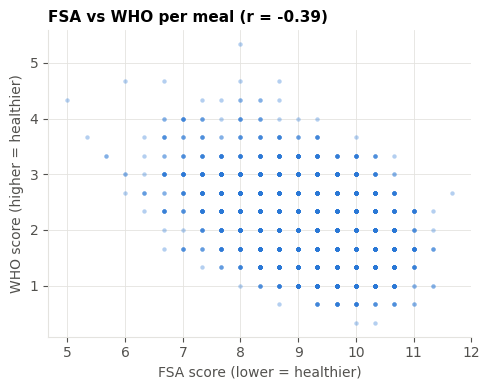

In [7]:
r = np.corrcoef(data.meal_health.fsa, data.meal_health.who)[0, 1]
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(data.meal_health.fsa, data.meal_health.who, s=10, color=BLUE, alpha=0.35, linewidths=0)
ax.set_xlabel("FSA score (lower = healthier)"); ax.set_ylabel("WHO score (higher = healthier)")
ax.set_title(f"FSA vs WHO per meal (r = {r:.2f})", loc="left")
fig.tight_layout(); fig.savefig("figures/fsa_vs_who.png", dpi=300, bbox_inches="tight"); plt.show()

## Step 6 · Notes for Section 3 (limitations & assumptions)

- **Implicit feedback.** An interaction means the user rated/reviewed the dishes of a meal on a recipe site, not that they actually ate it.
- **Limited representativeness.** All recipes and users come from a single recipe platform, so the data may not represent other populations or eating habits.
- **Generic health scores.** FSA/WHO scores are computed from nutrition information and are not tailored to individual conditions, allergies or dietary goals.
- **Popularity skew.** A small share of meals receives a large share of interactions (Fig. b), which favours popularity-based recommenders.
- **Split.** We use the official 8:1:1 split so results are comparable with the MealRec+ paper; every test user has training data (no cold-start users in MealRec+H).
- **No leakage.** User health profiles are computed from training interactions only (verified to match the official `user_fsa.txt`).